<a href="https://colab.research.google.com/github/sergiomorapardo/StochasticAITechniquesClass/blob/main/Notebooks/L14_HackathonFraming.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook: Hackathon Problem Framing — Pronóstico de recaudo a 30 días

**El reto en una frase:** una empresa de factoring quiere saber cuánto efectivo recibirá en los próximos 30 días por cada factura que tiene abierta.

Este notebook **no resuelve el reto**: muestra cómo plantearlo. Usa **una sola simulación** con datos sintéticos que recorre todo el camino: las tablas, el target, el corte, la vista minable, la fuga de información y la validación por fecha. Los nombres de columnas, los tipos de movimiento y las variables son **inventados**: mapearlos con el diccionario de datos real es parte del trabajo.

Ejecuten las celdas en orden; tarda unos segundos. Al final hay un repaso con respuestas para estudiar por su cuenta.

## Contenido

1. [El problema](#s1)
2. [Las tablas y la simulación](#s2)
3. [El target: qué cuenta como recaudo](#s3)
4. [El corte y la vista minable](#s4)
5. [Fuga de información y validación por fecha](#s5)
6. [Checklist, repaso y glosario](#s6)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

<a id="s1"></a>
## 1. El problema

Una empresa (el **cliente** del factor) vende a crédito y emite una factura que su comprador, el **pagador**, pagará en 30, 60 o 90 días. El **factor** le compra esa factura y le anticipa parte del valor; luego cobra al pagador. El factor sabe cuándo vence cada factura, pero **no sabe cuándo ni cuánto efectivo llegará**: hay pagos tardíos, pagos parciales, notas crédito y reversos.

| Pieza | Definición |
|---|---|
| **Pregunta de negocio** | ¿Cuánta caja entrará en los próximos 30 días por la cartera que ya compramos? |
| **Pregunta analítica** | Regresión: para cada factura abierta en una fecha de corte, estimar el efectivo neto que recibirá en los 30 días siguientes. |
| **Unidad de análisis** | Factura × fecha de corte (cierres de mes). |
| **Target** | Efectivo neto recibido en la ventana. Cero si no llega nada. |
| **Validación** | Por fecha de corte: se entrena con el pasado y se evalúa en el futuro. |
| **Métricas** | MAE por factura y error absoluto del total de la cartera, en dinero, frente a un pronóstico base. |

Es **regresión** porque el producto es un monto en dinero. Se pronostica **por factura** porque así se puede sumar por pagador, por cliente o para toda la cartera.

<a id="s2"></a>
## 2. Las tablas y la simulación

El reto trae cuatro archivos. Este diagrama muestra cómo se relacionan, con nombres genéricos:

<img src="https://mermaid.ink/img/ZXJEaWFncmFtCiAgICBQQUdBRE9SIHx8LS1veyBGQUNUVVJBIDogImRlYmUgcGFnYXIiCiAgICBGQUNUVVJBIHx8LS1veyBNT1ZJTUlFTlRPIDogInJlY2liZSIKICAgIEZBQ1RVUkEgfHwtLW98IENBUlRFUkFfQUxfQ09SVEUgOiAiYXBhcmVjZSBzaSBzaWd1ZSBhYmllcnRhIgoKICAgIFBBR0FET1IgewogICAgICAgIHN0cmluZyBpZF9wYWdhZG9yIFBLCiAgICAgICAgc3RyaW5nIHNlZ21lbnRvCiAgICB9CiAgICBGQUNUVVJBIHsKICAgICAgICBzdHJpbmcgaWRfZmFjdHVyYSBQSwogICAgICAgIHN0cmluZyBpZF9wYWdhZG9yIEZLCiAgICAgICAgZGF0ZSBmZWNoYV9jb21wcmEKICAgICAgICBkYXRlIGZlY2hhX3ZlbmNlCiAgICAgICAgZmxvYXQgdmFsb3IKICAgIH0KICAgIE1PVklNSUVOVE8gewogICAgICAgIHN0cmluZyBpZF9mYWN0dXJhIEZLCiAgICAgICAgZGF0ZSBmZWNoYQogICAgICAgIHN0cmluZyB0aXBvICJwYWdvLCByZXZlcnNvLCBjcmVkaXRvLCBjaWVycmUiCiAgICAgICAgZmxvYXQgY2FqYSAiZWZlY3Rpdm8gcXVlIGVudHJhIG8gc2FsZSIKICAgICAgICBmbG9hdCBkZXNjdWVudGEgImN1YW50byByZWR1Y2UgbGEgZGV1ZGEiCiAgICB9CiAgICBDQVJURVJBX0FMX0NPUlRFIHsKICAgICAgICBzdHJpbmcgaWRfZmFjdHVyYSBGSwogICAgICAgIGZsb2F0IHBlbmRpZW50ZQogICAgfQ==?type=png&bgColor=white" width="520" alt="Diagrama entidad-relación conceptual">

<details><summary>Ver el código Mermaid del diagrama</summary>

```mermaid
erDiagram
    PAGADOR ||--o{ FACTURA : "debe pagar"
    FACTURA ||--o{ MOVIMIENTO : "recibe"
    FACTURA ||--o| CARTERA_AL_CORTE : "aparece si sigue abierta"

    PAGADOR {
        string id_pagador PK
        string segmento
    }
    FACTURA {
        string id_factura PK
        string id_pagador FK
        date fecha_compra
        date fecha_vence
        float valor
    }
    MOVIMIENTO {
        string id_factura FK
        date fecha
        string tipo "pago, reverso, credito, cierre"
        float caja "efectivo que entra o sale"
        float descuenta "cuanto reduce la deuda"
    }
    CARTERA_AL_CORTE {
        string id_factura FK
        float pendiente
    }
```

</details>

| Entidad | Para qué sirve | Archivo del reto |
|---|---|---|
| **FACTURA** | La población: toda factura que puede aparecer en un corte | Purchases Advances |
| **MOVIMIENTO** | Calcular lo pendiente y el target | Collections |
| **PAGADOR** | Enriquecer con características del pagador | Debtor Information |
| **CARTERA_AL_CORTE** | La cartera a pronosticar; sirve para validar su reconstrucción | Invoice Aging |

**Cómo leer el diagrama.** `||--o{` significa "uno a muchos": un pagador tiene muchas facturas y una factura tiene muchos movimientos. `PK` es la llave y `FK` la columna que une con otra tabla. Con los datos reales, comprueben qué columnas identifican **una sola** factura antes de unir.

La siguiente función genera tablas parecidas a las tres primeras. Todo el notebook usa solo esta simulación. Pueden leer el código por encima: lo importante es la salida.

In [2]:
EFECTIVO = ["pago", "reverso_pago"]          # los únicos tipos que son dinero del pagador
HOY = pd.Timestamp("2026-11-03")             # fecha de la "foto" más reciente


def simulate(seed=7, n_facturas=8000, n_pagadores=40):
    """Genera pagadores, facturas y movimientos sintéticos. x1 y x3 son atributos anónimos de la factura."""
    rng = np.random.default_rng(seed)
    pagadores = pd.DataFrame({"id_pagador": [f"P{i:02d}" for i in range(n_pagadores)],
                              "segmento": rng.choice(["A", "B", "C"], n_pagadores)})
    ritmo = rng.normal(0, 30, n_pagadores)               # costumbre de pago de cada pagador (oculta)
    deriva = rng.choice([0, 0, 0, 25, -20], n_pagadores)  # algunos cambian con los años (oculto)

    p = rng.integers(n_pagadores, size=n_facturas)
    compra = pd.Timestamp("2022-12-01") + pd.to_timedelta(rng.integers(0, 1400, n_facturas), unit="D")
    vence = compra + pd.to_timedelta(rng.choice([30, 60, 90], n_facturas), unit="D")
    facturas = pd.DataFrame({"id_factura": [f"F{i:05d}" for i in range(n_facturas)],
                             "id_pagador": pagadores["id_pagador"].to_numpy()[p],
                             "fecha_compra": compra, "fecha_vence": vence,
                             "valor": np.round(np.exp(rng.normal(9, 0.5, n_facturas)), -1),
                             "x1": rng.normal(size=n_facturas), "x3": rng.normal(size=n_facturas)})

    anios = (compra - compra.min()).days / 365
    atraso = ritmo[p] + deriva[p] * anios + 15 * facturas["x1"] + rng.normal(0, 20, n_facturas)
    fecha_pago = np.maximum(vence + pd.to_timedelta(np.round(atraso), unit="D"), compra + pd.Timedelta(days=1))

    filas, dia = [], pd.Timedelta(days=1)
    for f, fp, r in zip(facturas.itertuples(), fecha_pago, rng.random(n_facturas) - 0.05 * facturas["x3"]):
        v = f.valor
        if r < 0.70:     # paga completo
            filas += [(f.id_factura, fp, "pago", v, v)]
        elif r < 0.82:   # paga una parte y el resto se va en una nota crédito
            filas += [(f.id_factura, fp, "pago", 0.85 * v, 0.85 * v),
                      (f.id_factura, fp + 5 * dia, "nota_credito", 0, 0.15 * v)]
        elif r < 0.90:   # paga, el pago se reversa y vuelve a pagar
            filas += [(f.id_factura, fp, "pago", v, v), (f.id_factura, fp + 4 * dia, "reverso_pago", -v, -v),
                      (f.id_factura, fp + 20 * dia, "pago", v, v)]
        else:            # paga una parte y la factura se cierra con la reserva
            filas += [(f.id_factura, fp, "pago", 0.8 * v, 0.8 * v),
                      (f.id_factura, fp + 10 * dia, "cierre_reserva", 0, 0.2 * v)]
    movs = pd.DataFrame(filas, columns=["id_factura", "fecha", "tipo", "caja", "descuenta"])
    movs = movs[movs["fecha"] <= HOY].sort_values(["id_factura", "fecha"]).reset_index(drop=True)
    facturas = facturas[facturas["fecha_compra"] <= HOY].reset_index(drop=True)
    return pagadores, facturas, movs


pagadores, facturas, movs = simulate()
print(f"{len(pagadores)} pagadores | {len(facturas):,} facturas | {len(movs):,} movimientos")
display(facturas.head(3), movs.head(5))

40 pagadores | 8,000 facturas | 10,830 movimientos


,id_factura,id_pagador,fecha_compra,fecha_vence,valor,x1,x3
0,F00000,P30,2025-04-02,2025-06-01,"5,830.00",-0.88,0.68
1,F00001,P37,2025-08-06,2025-10-05,"7,360.00",0.92,1.03
2,F00002,P09,2026-02-25,2026-03-27,"18,470.00",-0.75,1.91


,id_factura,fecha,tipo,caja,descuenta
0,F00000,2025-04-27,pago,"5,830.00","5,830.00"
1,F00001,2025-11-09,pago,"7,360.00","7,360.00"
2,F00002,2026-04-21,pago,"18,470.00","18,470.00"
3,F00003,2023-10-09,pago,"7,100.00","7,100.00"
4,F00004,2023-08-28,pago,"3,660.00","3,660.00"


Cada movimiento tiene dos montos: `caja` (dinero que entra o sale) y `descuenta` (cuánto reduce la deuda). No siempre coinciden: una nota crédito reduce la deuda sin que entre dinero.

> El simulador es una caricatura. En los datos reales hay más tipos de movimiento, llaves que comprobar y fechas de registro que pueden ser retroactivas.

<a id="s3"></a>
## 3. El target: qué cuenta como recaudo

| Tipo (inventado) | ¿Es efectivo del pagador? |
|---|---|
| `pago` | **Sí** |
| `reverso_pago` | **Sí**, con su signo negativo |
| `nota_credito` | No: reduce la deuda, pero no entra dinero |
| `cierre_reserva` | No: el factor cierra la factura con la reserva que retuvo |

**La regla:** el target es la **suma algebraica** de la `caja` de pagos y reversos en los días `T+1` a `T+30`. El reverso ya viene negativo, así que resta solo.

Miremos una factura con reverso y luego todo lo que pasó en la ventana del corte del 31-ago-2026:

In [3]:
T = pd.Timestamp("2026-08-31")
H = pd.Timedelta(days=30)

ejemplo = movs.loc[movs["tipo"] == "reverso_pago", "id_factura"].iloc[0]
display(movs[movs["id_factura"] == ejemplo])

ventana = movs[(movs["fecha"] > T) & (movs["fecha"] <= T + H)]
print(f"Movimientos en la ventana del corte {T.date()}: {len(ventana)}")
print(f"Correcto, pagos + reversos:          {ventana.loc[ventana['tipo'].isin(EFECTIVO), 'caja'].sum():>12,.0f}")
print(f"Error 1, sumar todo lo que descuenta: {ventana['descuenta'].sum():>12,.0f}  <- cuenta créditos y cierres como caja")
print(f"Error 2, sumar solo los pagos:        {ventana.loc[ventana['tipo'] == 'pago', 'caja'].sum():>12,.0f}  <- ignora los reversos")

,id_factura,fecha,tipo,caja,descuenta
4,F00004,2023-08-28,pago,"3,660.00","3,660.00"
5,F00004,2023-09-01,reverso_pago,"-3,660.00","-3,660.00"
6,F00004,2023-09-17,pago,"3,660.00","3,660.00"


Movimientos en la ventana del corte 2026-08-31: 225
Correcto, pagos + reversos:             1,452,870
Error 1, sumar todo lo que descuenta:    1,505,894  <- cuenta créditos y cierres como caja
Error 2, sumar solo los pagos:           1,558,480  <- ignora los reversos


**Cómo leer el resultado.** La factura del ejemplo pagó, el pago se reversó y volvió a pagar: entró su valor una sola vez. Los dos errores sobreestiman el recaudo: el primero cuenta como dinero lo que no lo es y el segundo olvida el dinero que se devolvió.

<a id="s4"></a>
## 4. El corte y la vista minable

Un **corte** `T` es una foto de la cartera, como si estuviéramos parados en ese día sin saber el futuro. Hay tres reglas:

1. **Población:** facturas compradas hasta `T` y con pendiente mayor que cero en `T`.
2. **Variables:** solo con información **hasta** `T`.
3. **Target:** efectivo entre `T+1` y `T+30`.

Repetir la foto en cada cierre de mes y apilar los resultados da la **vista minable**: una fila por factura y corte.

<img src="https://mermaid.ink/img/Zmxvd2NoYXJ0IFRECiAgICBBWyJGYWN0dXJhcyB5IG1vdmltaWVudG9zIl0gLS0-IEJbIkVsZWdpciB1biBjb3J0ZSBUPGJyLz4oY2llcnJlIGRlIG1lcykiXQogICAgQiAtLT4gQ1siUG9ibGFjacOzbjogZmFjdHVyYXMgY29tcHJhZGFzPGJyLz5oYXN0YSBUIHkgY29uIHBlbmRpZW50ZSBlbiBUIl0KICAgIEMgLS0-IERbIlZhcmlhYmxlczogc29sbyBjb248YnIvPmluZm9ybWFjacOzbiBoYXN0YSBUIl0KICAgIEMgLS0-IEVbIlRhcmdldDogZWZlY3Rpdm8gbmV0bzxici8-ZW50cmUgVCsxIHkgVCszMCJdCiAgICBEIC0tPiBGWyJGaWxhcyBmYWN0dXJhIMOXIGNvcnRlIl0KICAgIEUgLS0-IEYKICAgIEYgLS0-IEd7IsK_UXVlZGFuIGNvcnRlcz8ifQogICAgRyAtLSAic8OtIiAtLT4gQgogICAgRyAtLSAibm8iIC0tPiBIWyJWaXN0YSBtaW5hYmxlIl0=?type=png&bgColor=white" width="360" alt="Flujo de construcción de la vista minable">

<details><summary>Ver el código Mermaid del diagrama</summary>

```mermaid
flowchart TD
    A["Facturas y movimientos"] --> B["Elegir un corte T<br/>(cierre de mes)"]
    B --> C["Población: facturas compradas<br/>hasta T y con pendiente en T"]
    C --> D["Variables: solo con<br/>información hasta T"]
    C --> E["Target: efectivo neto<br/>entre T+1 y T+30"]
    D --> F["Filas factura × corte"]
    E --> F
    F --> G{"¿Quedan cortes?"}
    G -- "sí" --> B
    G -- "no" --> H["Vista minable"]
```

</details>

La función `build_cut` aplica las tres reglas. Las variables `x1` y `x3` son atributos anónimos de la factura. `x2` es una variable de historia: la fracción de facturas del pagador que recibió dinero **el mes anterior al corte**. Usa solo información conocida en `T`.

`x_fuga` es la misma idea pero mirando **el mes siguiente**. La incluimos a propósito para mostrar en la sección 5 qué pasa cuando una variable usa el futuro.

In [4]:
def open_at(T, facturas, movs):
    """Facturas compradas hasta T con su pendiente en T (valor menos lo descontado hasta T)."""
    aplicado = movs[movs["fecha"] <= T].groupby("id_factura")["descuenta"].sum()
    f = facturas[facturas["fecha_compra"] <= T].copy()
    f["pendiente"] = f["valor"] - f["id_factura"].map(aplicado).fillna(0)
    return f[f["pendiente"] > 0.5]


def cash_between(movs, ini, fin):
    """Efectivo neto (pagos + reversos) por factura en (ini, fin]."""
    m = movs[(movs["fecha"] > ini) & (movs["fecha"] <= fin) & movs["tipo"].isin(EFECTIVO)]
    return m.groupby("id_factura")["caja"].sum()


def payer_rate(abiertas, movs, ini, fin):
    """Fracción de las facturas abiertas de cada pagador que recibió dinero en (ini, fin]."""
    cobro = abiertas["id_factura"].map(cash_between(movs, ini, fin)).fillna(0) > 0
    return cobro.groupby(abiertas["id_pagador"]).mean()


def build_cut(T, facturas, movs, h=30):
    fin = T + pd.Timedelta(days=h)
    corte = open_at(T, facturas, movs)                                                   # regla 1
    corte["corte"] = T
    corte["target"] = corte["id_factura"].map(cash_between(movs, T, fin)).fillna(0)     # regla 3
    prev = T - pd.offsets.MonthEnd(1)
    corte["x2"] = corte["id_pagador"].map(payer_rate(open_at(prev, facturas, movs), movs, prev, T))  # regla 2: pasado
    corte["x_fuga"] = corte["id_pagador"].map(payer_rate(corte, movs, T, fin))                        # ¡usa el futuro!
    return corte[["id_factura", "id_pagador", "corte", "x1", "x2", "x3", "pendiente", "x_fuga", "target"]]


un_corte = build_cut(T, facturas, movs)
print(f"Corte {T.date()}: {(facturas['fecha_compra'] <= T).sum():,} facturas compradas, "
      f"{len(un_corte)} abiertas, {(un_corte['target'] == 0).mean():.0%} con target 0")

cortes = pd.date_range("2023-01-31", "2026-08-31", freq="ME")
panel = pd.concat([build_cut(c, facturas, movs) for c in cortes], ignore_index=True)
panel["x2"] = panel["x2"].fillna(panel["x2"].mean())
print(f"Vista minable: {len(panel):,} filas | {len(cortes)} cortes | "
      f"{panel.groupby('id_factura').size().mean():.1f} cortes por factura en promedio")

# Una factura que aparece en varios cortes y cuyo pendiente cambia entre cortes
resumen = panel.groupby("id_factura").agg(n=("corte", "size"), pendientes=("pendiente", "nunique"))
varios = resumen[(resumen["n"].between(2, 4)) & (resumen["pendientes"] > 1)].index[0]
display(panel.loc[panel["id_factura"] == varios, ["id_factura", "corte", "pendiente", "x2", "target"]],
        movs[movs["id_factura"] == varios])

Corte 2026-08-31: 7,840 facturas compradas, 351 abiertas, 67% con target 0


Vista minable: 14,703 filas | 44 cortes | 2.4 cortes por factura en promedio


,id_factura,corte,pendiente,x2,target
256,F00040,2023-02-28,"8,870.00",0.22,0.00
582,F00040,2023-03-31,"8,870.00",0.69,"7,539.50"
924,F00040,2023-04-30,"1,330.50",0.45,0.00


,id_factura,fecha,tipo,caja,descuenta
54,F00040,2023-04-28,pago,"7,539.50","7,539.50"
55,F00040,2023-05-03,nota_credito,0.00,"1,330.50"


**Cómo leer la salida.**

- La mayoría de las facturas compradas ya no está abierta en el corte: se pagaron antes. **No entran.**
- Muchas facturas abiertas tienen target 0: no pagaron en la ventana. **No se borran**: el modelo tiene que aprender que a veces no llega nada.
- La factura del ejemplo aparece en **tres cortes**. En el primero su target es 0 porque no pagó en esa ventana. En el segundo recibe un pago parcial. En el tercero su pendiente ya es solo lo que faltaba, y su target es 0 porque ese saldo se cerró con una nota crédito, no con dinero.

Con los datos reales, escriban la construcción como una **función de la fecha de corte**, como `build_cut`. Así la repiten en todos los meses y la aplican a la cartera actual, que es lo que pide el enunciado.

<a id="s5"></a>
## 5. Fuga de información y validación por fecha

**Validación por fecha.** Se entrena con los cortes hasta el 30-jun-2026, se elige el modelo en el corte de validación (31-jul) y se reporta **una sola vez** en el de prueba (31-ago). No usamos `train_test_split` ni K-fold aleatorio ([L6](L6_CrossValidation.ipynb)): la misma factura está en varios cortes y el comportamiento cambia con el tiempo. Una partición aleatoria entrenaría con el futuro y pondría "gemelas" de la misma factura en entrenamiento y prueba.

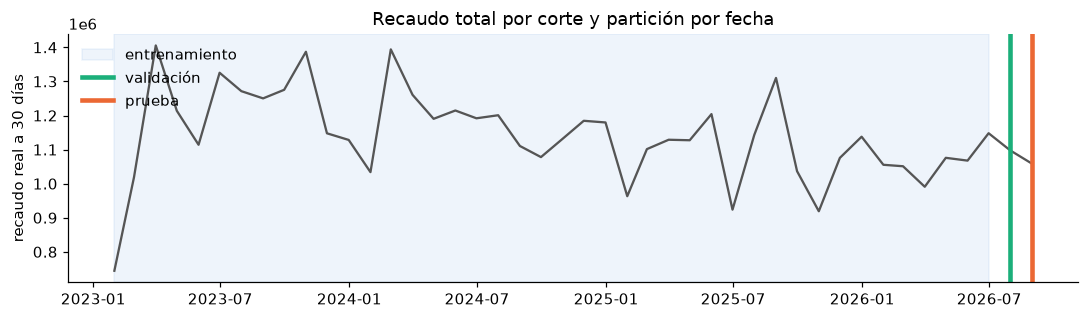

In [5]:
TRAIN_FIN, VAL, TEST = pd.Timestamp("2026-06-30"), pd.Timestamp("2026-07-31"), pd.Timestamp("2026-08-31")
tr = panel[panel["corte"] <= TRAIN_FIN]
va = panel[panel["corte"] == VAL]
te = panel[panel["corte"] == TEST]

total = panel.groupby("corte")["target"].sum()
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(total.index, total, color="#555555", lw=1.5)
ax.axvspan(cortes[0], TRAIN_FIN, color="#2a78d6", alpha=0.08, label="entrenamiento")
ax.axvline(VAL, color="#1baf7a", lw=3, label="validación")
ax.axvline(TEST, color="#eb6834", lw=3, label="prueba")
ax.set_ylabel("recaudo real a 30 días")
ax.set_title("Recaudo total por corte y partición por fecha")
ax.legend(loc="upper left", frameon=False)
plt.tight_layout(); plt.show()

**Fuga de información.** Una variable tiene fuga si usa datos que **no existían en la fecha de corte**. El modelo se ve excelente en la evaluación y falla al usarse de verdad, porque el futuro todavía no ha pasado.

Comparemos tres pronósticos en el corte de validación:

- **Piso:** tasa global de recaudo del entrenamiento × pendiente. Es la regla simple que cualquier modelo debe superar. El enunciado pide además un pronóstico base por vencimientos: piensen ustedes cómo construirlo.
- **Árbol** ([L9](L9_NaiveBayes_CART.ipynb)) con `x1`, `x2` y `x3`. Predice la fracción del pendiente que se cobrará y la multiplica por el pendiente.
- **Árbol + `x_fuga`**: el mismo árbol con la variable que mira el mes siguiente.

In [6]:
def mae(y, yhat):
    return np.mean(np.abs(np.asarray(y) - np.asarray(yhat)))


def fit_tree(df, cols):
    frac = (df["target"] / df["pendiente"]).clip(0, 1)
    return DecisionTreeRegressor(max_depth=4, min_samples_leaf=30, random_state=0).fit(df[cols], frac)


SIN_FUGA, CON_FUGA = ["x1", "x2", "x3"], ["x1", "x2", "x3", "x_fuga"]
tasa = tr["target"].sum() / tr["pendiente"].sum()
pronosticos = {
    "Piso: tasa global × pendiente": tasa * va["pendiente"],
    "Árbol (x1, x2, x3)": fit_tree(tr, SIN_FUGA).predict(va[SIN_FUGA]) * va["pendiente"],
    "Árbol + x_fuga (¡fuga!)": fit_tree(tr, CON_FUGA).predict(va[CON_FUGA]) * va["pendiente"],
}
tabla = pd.DataFrame({nombre: {"MAE por factura": mae(va["target"], y),
                               "Total pronosticado": np.sum(y),
                               "Error abs. del total": abs(np.sum(y) - va["target"].sum())}
                      for nombre, y in pronosticos.items()}).T
print(f"Validación {VAL.date()}: {len(va)} facturas abiertas | recaudo real {va['target'].sum():,.0f}")
display(tabla)

Validación 2026-07-31: 335 facturas abiertas | recaudo real 1,097,384


,MAE por factura,Total pronosticado,Error abs. del total
Piso: tasa global × pendiente,"4,194.38","1,178,206.06","80,822.06"
"Árbol (x1, x2, x3)","4,121.11","1,097,349.37",34.63
Árbol + x_fuga (¡fuga!),"3,458.81","1,087,418.62","9,965.38"


**Cómo leer la tabla.**

- **La fila con fuga gana por mucho, y es falsa.** El día que pronostiquen la cartera actual, el mes siguiente no ha pasado y `x_fuga` no se puede calcular. Prueba rápida para cada variable: *¿podía calcular este número el día del corte?* Si una variable mejora el modelo "demasiado", sospechen de ella primero.
- **El árbol sin fuga apenas mejora el MAE del piso.** Con variables anónimas no hay mucho que aprender. Ahí está el trabajo de la hackatón: diseñar variables con sentido de negocio, siempre con información hasta `T`.
- **Las dos métricas pueden contar historias distintas.** Los errores por factura pueden compensarse al sumar y dar un total acertado. Reporten ambas.

Elegimos en validación entre los modelos **sin fuga** y solo entonces miramos la prueba, una vez:

In [7]:
validos = tabla.drop(index="Árbol + x_fuga (¡fuga!)")
elegido = validos["MAE por factura"].idxmin()
hasta_val = panel[panel["corte"] <= VAL]          # se reentrena con todo lo conocido al cierre de validación
if elegido.startswith("Piso"):
    y_test = hasta_val["target"].sum() / hasta_val["pendiente"].sum() * te["pendiente"]
else:
    y_test = fit_tree(hasta_val, SIN_FUGA).predict(te[SIN_FUGA]) * te["pendiente"]
print(f"Elegido en validación: {elegido}")
print(f"Prueba {TEST.date()}: MAE por factura {mae(te['target'], y_test):,.0f} | total real {te['target'].sum():,.0f} | "
      f"pronosticado {np.sum(y_test):,.0f}")

Elegido en validación: Árbol (x1, x2, x3)
Prueba 2026-08-31: MAE por factura 3,791 | total real 1,058,446 | pronosticado 1,102,057


> **Un detalle de fechas.** Para evaluar en un corte `T` solo se puede entrenar con cortes cuyo target ya se conocía en `T`. El corte del 30-jun tiene su ventana hasta el 30-jul, antes de la validación del 31-jul. Por eso es el último corte de entrenamiento.

<a id="s6"></a>
## 6. Checklist, repaso y glosario

### Entregables al cierre de la hackatón

- [ ] **Notebook reproducible**: integración, limpieza, vista minable, modelos y evaluación.
- [ ] **Vista minable documentada**: unidad de análisis, llaves, reglas del target y variables justificadas.
- [ ] **Modelo que funciona para cualquier fecha de corte** y devuelve un monto por factura.
- [ ] **Pronóstico de la cartera actual**: por factura y con totales por cliente, pagador y cartera.
- [ ] **Comparación con el pronóstico base** por vencimientos.
- [ ] **Pitch** para Operaciones: resultados, limitaciones y recomendaciones.

**Antes de la hackatón:** revisen las bases, el enunciado y el diccionario, traigan preguntas para la empresa y busquen literatura sobre *cash-flow forecasting* o *invoice payment prediction*.

### Los seis errores que más cuestan

1. Contar como efectivo lo que no lo es (sección 3).
2. Borrar las facturas con target 0 (sección 4).
3. Usar información posterior al corte (sección 5).
4. Evaluar con particiones aleatorias (sección 5).
5. No comparar contra un pronóstico base (sección 5).
6. Unir tablas con una llave que no identifica una sola factura (sección 2).

### Repaso

1. Una factura de 5.000 recibe un pago de 5.000 y una semana después un reverso de −5.000, ambos en la ventana. ¿Cuál es su target?

   <details><summary>Ver respuesta</summary>

   0: el pago se anuló.

   </details>

2. Una factura se cierra con la reserva dentro de la ventana. ¿Cuánto aporta al target?

   <details><summary>Ver respuesta</summary>

   0: se cerró, pero no entró efectivo del pagador.

   </details>

3. Una factura se compró el 15-sep-2026. ¿Entra al corte del 31-ago-2026?

   <details><summary>Ver respuesta</summary>

   No: en esa fecha todavía no existía para el factor.

   </details>

4. Un equipo calcula el "porcentaje de facturas que el pagador pagó tarde" con toda la base y lo usa en todos los cortes. ¿Hay fuga?

   <details><summary>Ver respuesta</summary>

   Sí: en los cortes antiguos ese porcentaje incluye facturas que se pagaron después del corte. Debe calcularse en cada corte con lo conocido hasta `T`.

   </details>

5. Un compañero reporta un error muy bajo con `train_test_split(shuffle=True)` sobre la vista minable. ¿Qué le dirían?

   <details><summary>Ver respuesta</summary>

   Que repita la evaluación partiendo por fecha de corte: la partición aleatoria es optimista porque la misma factura aparece en varios cortes y el modelo entrena con el futuro.

   </details>

### Glosario

| Término | Significado |
|---|---|
| **Factor / cliente / pagador** | Quien compra la factura / quien la vende / quien debe pagarla. |
| **Reserva** | Parte del valor que el factor retiene al comprar; cerrar con ella no es efectivo del pagador. |
| **Nota crédito** | Reducción de la deuda sin entrada de dinero. |
| **Reverso** | Anulación de un pago; viene con signo negativo. |
| **Corte `T`** | Fecha en que se observa la cartera; en el reto, cierres de mes. |
| **Pendiente** | Lo que falta por aplicar a la factura en el corte. |
| **Target** | Efectivo neto (pagos + reversos) entre `T+1` y `T+30`. |
| **Vista minable** | Tabla con una fila por factura × corte, sus variables y su target. |
| **Fuga de información** | Usar en una variable datos que no existían en la fecha de corte. |
| **Piso / pronóstico base** | Regla simple que el modelo debe superar. |
| **MAE** | Promedio de \|pronóstico − real\|. |

**Para cerrar:** el reto no es elegir el algoritmo más sofisticado, sino plantear bien el problema. Definan el target con las reglas del negocio, construyan la vista minable sin fuga y evalúen como si estuvieran parados en la fecha de corte.